# Adult Income ML: Parts 2, 3 and 4

This notebook uses the Adult dataset from OpenML, version 2, to predict whether income exceeds 50K. Execute all cells in order. All results are calculated by code rather than copied from screenshots.

The final cell builds `README.md` and saves `figures/learning_curve.png`. It replaces the README in the current folder. Back up any existing README before running this cell.

## Part 2: Setup, split and one reusable preprocessor

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer
from sklearn.inspection import permutation_importance
from sklearn.base import clone

FixedSeed = 42
random.seed(FixedSeed)
np.random.seed(FixedSeed)
torch.manual_seed(FixedSeed)

print("Python libraries loaded")

Python libraries loaded


In [2]:
Dataset = fetch_openml(name="adult", version=2, as_frame=True)
X = Dataset.data.replace("?", np.nan)
y = (Dataset.target.astype(str).str.strip() == ">50K").astype(int)

print("Rows:", len(X))
print("Columns:", len(X.columns))
print("Target class counts:")
print(y.value_counts())

XTrain, XTest, YTrain, YTest = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=FixedSeed,
    stratify=y
)

NumCols = XTrain.select_dtypes(include="number").columns.tolist()
CatCols = XTrain.select_dtypes(include=["object", "category"]).columns.tolist()

NumSteps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

CatSteps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

Preprocessor = ColumnTransformer([
    ("num", NumSteps, NumCols),
    ("cat", CatSteps, CatCols)
])

print("Training rows:", len(XTrain))
print("Test rows:", len(XTest))

Rows: 48842
Columns: 14
Target class counts:
class
0    37155
1    11687
Name: count, dtype: int64
Training rows: 39073
Test rows: 9769


### What data leakage means

Data leakage means information from outside the training data influences how the model learns. For example, fitting an imputer or a scaler to all rows before the train/test split would let the preprocessing learn from the test set. Here the split happens first, and preprocessing stays inside each scikit-learn `Pipeline` for classical models. During cross-validation, each fold learns its preprocessing only from that fold's training portion. The test data is not used for selecting model parameters.

### Baselines with five-fold cross-validation

The majority-class dummy model gives a reference score. Logistic regression is a stronger baseline. Metrics are computed only on held-out cross-validation folds from the training data.

In [3]:
Cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=FixedSeed)

ScoresToUse = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

BaselineModels = {
    "Majority Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=FixedSeed)
}

BaselineRows = []

for ModelName in BaselineModels:
    Model = BaselineModels[ModelName]
    FullModel = Pipeline([
        ("preprocess", clone(Preprocessor)),
        ("model", Model)
    ])
    Results = cross_validate(
        FullModel, XTrain, YTrain,
        cv=Cv, scoring=ScoresToUse, n_jobs=1
    )

    Row = {"Model": ModelName}
    for Metric in ScoresToUse:
        Values = Results["test_" + Metric]
        Row[Metric + " mean"] = Values.mean()
        Row[Metric + " std"] = Values.std()
    BaselineRows.append(Row)

BaselineTable = pd.DataFrame(BaselineRows)
display(BaselineTable.round(4))

,Model,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,roc_auc mean,roc_auc std
0,Majority Dummy,0.7607,0.0000,0.0000,0.000,0.0000,0.000,0.0000,0.0000,0.5000,0.0000
1,Logistic Regression,0.8513,0.0051,0.7325,0.017,0.5966,0.007,0.6576,0.0098,0.9055,0.0038


Accuracy alone is weak on this dataset because the income classes are not balanced, so predicting the larger class can still look accurate. Precision, recall, F1 and ROC AUC reveal different kinds of errors that accuracy hides.

## Part 3: Model comparison and parameter search

In [4]:
ModelFamilies = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=FixedSeed),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=FixedSeed, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=FixedSeed)
}

CvRows = []

for ModelName in ModelFamilies:
    FullModel = Pipeline([
        ("preprocess", clone(Preprocessor)),
        ("model", ModelFamilies[ModelName])
    ])
    Results = cross_validate(
        FullModel, XTrain, YTrain,
        cv=Cv, scoring={"roc_auc": "roc_auc", "f1": "f1"}, n_jobs=1
    )

    CvRows.append({
        "Model": ModelName,
        "ROC AUC mean": Results["test_roc_auc"].mean(),
        "ROC AUC std": Results["test_roc_auc"].std(),
        "F1 mean": Results["test_f1"].mean(),
        "F1 std": Results["test_f1"].std()
    })

CvTable = pd.DataFrame(CvRows)
display(CvTable.round(4))

,Model,ROC AUC mean,ROC AUC std,F1 mean,F1 std
0,Logistic Regression,0.9055,0.0038,0.6576,0.0098
1,Random Forest,0.9009,0.0043,0.6653,0.0089
2,Hist Gradient Boosting,0.9276,0.0024,0.7082,0.0085


The three model families use the same features, the same training split, and the same five CV folds. The tuning grid below varies learning rate, tree depth and number of boosting iterations.

In [5]:
BoostingPipeline = Pipeline([
    ("preprocess", clone(Preprocessor)),
    ("model", HistGradientBoostingClassifier(random_state=FixedSeed))
])

ParameterGrid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [5, 10],
    "model__max_iter": [100, 200]
}

Search = GridSearchCV(
    BoostingPipeline,
    ParameterGrid,
    cv=Cv,
    scoring="roc_auc",
    n_jobs=1
)
Search.fit(XTrain, YTrain)

BestModel = Search.best_estimator_
print("Tried parameters:", ParameterGrid)
print("Best parameters:", Search.best_params_)
print("Best mean CV ROC AUC:", round(Search.best_score_, 4))

Tried parameters: {'model__learning_rate': [0.05, 0.1], 'model__max_depth': [5, 10], 'model__max_iter': [100, 200]}
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 10, 'model__max_iter': 200}
Best mean CV ROC AUC: 0.9275


### Fit the comparison models once and evaluate the held-out test set

The test set is used for final reporting only. Hyperparameters must not be changed after seeing these test results. Logistic regression and random forest are fitted on the training set; the tuned boosting pipeline is already fitted by `GridSearchCV`.

In [6]:
FittedModels = {}

for ModelName in ["Logistic Regression", "Random Forest"]:
    FullModel = Pipeline([
        ("preprocess", clone(Preprocessor)),
        ("model", clone(ModelFamilies[ModelName]))
    ])
    FullModel.fit(XTrain, YTrain)
    FittedModels[ModelName] = FullModel

FittedModels["Tuned Hist Gradient Boosting"] = BestModel


def MeasureResults(Name, TrueValues, Predictions, Probabilities):
    Row = {}
    Row["Model"] = Name
    Row["Accuracy"] = accuracy_score(TrueValues, Predictions)
    Row["Precision"] = precision_score(TrueValues, Predictions, zero_division=0)
    Row["Recall"] = recall_score(TrueValues, Predictions, zero_division=0)
    Row["F1"] = f1_score(TrueValues, Predictions, zero_division=0)
    Row["ROC AUC"] = roc_auc_score(TrueValues, Probabilities)
    return Row


TestRows = []

for ModelName in FittedModels:
    Model = FittedModels[ModelName]
    Predictions = Model.predict(XTest)
    Probabilities = Model.predict_proba(XTest)[:, 1]
    TestRows.append(MeasureResults(ModelName, YTest, Predictions, Probabilities))

TestTable = pd.DataFrame(TestRows)
display(TestTable.round(4))

BestPredictions = BestModel.predict(XTest)
BestProbabilities = BestModel.predict_proba(XTest)[:, 1]

print("Tuned boosting confusion matrix:")
print(confusion_matrix(YTest, BestPredictions))
print("CV versus test ROC AUC:")
print("CV:", round(Search.best_score_, 4))
print("Test:", round(roc_auc_score(YTest, BestProbabilities), 4))
print("Difference:", round(roc_auc_score(YTest, BestProbabilities) - Search.best_score_, 4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.8524,0.7414,0.5885,0.6562,0.9042
1,Random Forest,0.8602,0.7430,0.6356,0.6851,0.9038
2,Tuned Hist Gradient Boosting,0.8768,0.7929,0.6565,0.7183,0.9290


Tuned boosting confusion matrix:
[[7030  401]
 [ 803 1535]]
CV versus test ROC AUC:
CV: 0.9275
Test: 0.929
Difference: 0.0014


The difference between CV and test performance shows how the model behaved on the holdout data. A small difference does not prove that leakage is absent. The split and the fitted preprocessing pipeline are the safeguards against leakage.

### Permutation importance

Permutation importance measures the drop in ROC AUC when one original input column is shuffled. Correlated columns, such as `marital-status` and `relationship`, can share importance; a small score for one of them does not mean it has no relationship with income.

,Feature,Importance
5,marital-status,0.0999
10,capital-gain,0.0615
0,age,0.0411
4,education-num,0.0322
11,capital-loss,0.0127
12,hours-per-week,0.0126
6,occupation,0.0105
7,relationship,0.0025
1,workclass,0.0021
9,sex,0.0013


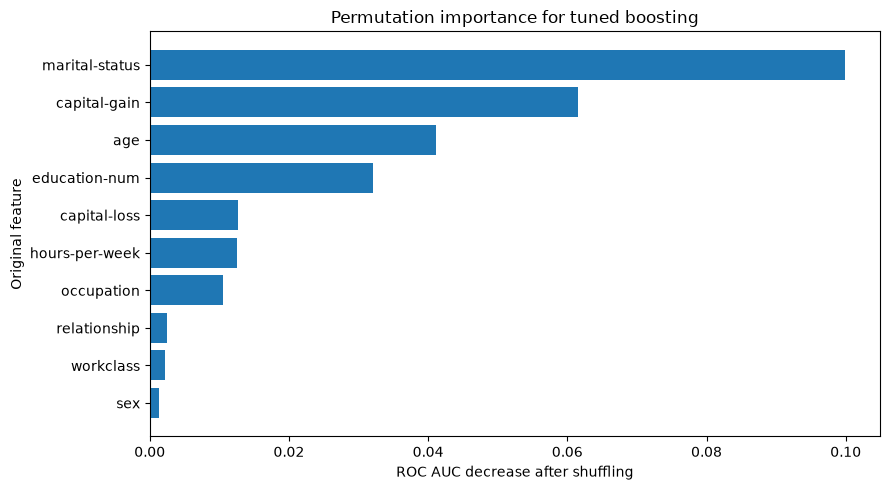

In [7]:
Importance = permutation_importance(
    BestModel, XTest, YTest,
    scoring="roc_auc", n_repeats=3,
    random_state=FixedSeed, n_jobs=1
)

ImportanceTable = pd.DataFrame({
    "Feature": XTest.columns,
    "Importance": Importance.importances_mean
})
ImportanceTable = ImportanceTable.sort_values("Importance", ascending=False)

display(ImportanceTable.head(10).round(4))

TopImportance = ImportanceTable.head(10).sort_values("Importance")
plt.figure(figsize=(9, 5))
plt.barh(TopImportance["Feature"], TopImportance["Importance"])
plt.xlabel("ROC AUC decrease after shuffling")
plt.ylabel("Original feature")
plt.title("Permutation importance for tuned boosting")
plt.tight_layout()
plt.show()

### Error analysis

`FN` means a person actually belongs to the >50K class but was predicted <=50K. `TP` means a correct >50K prediction, and `TN` means a correct <=50K prediction. We compare numeric and categorical features across these groups and select five examples using explicit conditions.

In [8]:
Analysis = XTest.copy()
Analysis["True"] = YTest
Analysis["Predicted"] = BestPredictions

Analysis["Outcome"] = "FP"
Analysis.loc[(Analysis["True"] == 1) & (Analysis["Predicted"] == 0), "Outcome"] = "FN"
Analysis.loc[(Analysis["True"] == 1) & (Analysis["Predicted"] == 1), "Outcome"] = "TP"
Analysis.loc[(Analysis["True"] == 0) & (Analysis["Predicted"] == 0), "Outcome"] = "TN"

print("Count by outcome:")
print(Analysis["Outcome"].value_counts())

print("Numeric features by outcome:")
NumericSummary = Analysis.groupby("Outcome", observed=True)[
    ["education-num", "hours-per-week", "capital-gain"]
].agg(["mean", "median"])
display(NumericSummary.round(2))

print("Occupation by outcome, top values:")
OccupationTable = pd.crosstab(Analysis["occupation"], Analysis["Outcome"], normalize="columns")
display(OccupationTable.sort_values("FN", ascending=False).head(10).round(3))

print("Sex by outcome:")
SexOutcomeTable = pd.crosstab(Analysis["sex"], Analysis["Outcome"], normalize="columns")
display(SexOutcomeTable.round(3))

print("Education number by outcome:")
EducationOutcome = Analysis.groupby(["education-num", "Outcome"], observed=True).size().unstack(fill_value=0)
display(EducationOutcome)

print("Working hours group by outcome:")
Analysis["HoursGroup"] = pd.cut(Analysis["hours-per-week"], bins=[0, 29, 40, 50, np.inf], labels=["1-29", "30-40", "41-50", "51+"])
display(pd.crosstab(Analysis["HoursGroup"], Analysis["Outcome"], normalize="columns").round(3))

print("Capital gain group by outcome:")
Analysis["GainGroup"] = "0"
Analysis.loc[Analysis["capital-gain"] > 0, "GainGroup"] = ">0"
display(pd.crosstab(Analysis["GainGroup"], Analysis["Outcome"], normalize="columns").round(3))

Count by outcome:
Outcome
TN    7030
TP    1535
FN     803
FP     401
Name: count, dtype: int64
Numeric features by outcome:


education-num        hours-per-week        capital-gain       
                 mean median           mean median         mean median
Outcome                                                               
FN              10.08   10.0          44.12   40.0        26.71    0.0
FP              12.00   13.0          46.70   44.0       167.44    0.0
TN               9.45    9.0          38.17   40.0       142.94    0.0
TP              12.40   13.0          46.26   44.0      6704.79    0.0

Occupation by outcome, top values:


Outcome,FN,FP,TN,TP
occupation,,,,
Craft-repair,0.226,0.069,0.137,0.071
Sales,0.139,0.161,0.109,0.136
Prof-specialty,0.132,0.207,0.087,0.317
Exec-managerial,0.103,0.343,0.078,0.311
Transport-moving,0.093,0.026,0.062,0.017
Adm-clerical,0.086,0.097,0.145,0.044
Machine-op-inspct,0.055,0.015,0.086,0.016
Other-service,0.045,0.005,0.142,0.007
Tech-support,0.040,0.036,0.032,0.039


Sex by outcome:


Outcome,FN,FP,TN,TP
sex,,,,
Female,0.188,0.13,0.405,0.137
Male,0.812,0.87,0.595,0.863


... (2 outputs left out)

Working hours group by outcome:


Outcome,FN,FP,TN,TP
HoursGroup,,,,
1-29,0.045,0.015,0.166,0.014
30-40,0.558,0.469,0.623,0.464
41-50,0.235,0.299,0.135,0.320
51+,0.162,0.217,0.076,0.203


Capital gain group by outcome:


Outcome,FN,FP,TN,TP
GainGroup,,,,
0,0.994,0.973,0.957,0.661
>0,0.006,0.027,0.043,0.339


In [9]:
Errors = Analysis[Analysis["Outcome"].isin(["FN", "FP"])].copy()
ExampleRules = [
    ("FN, high education", (Errors["Outcome"] == "FN") & (Errors["education-num"] >= 13)),
    ("FN, positive capital gain", (Errors["Outcome"] == "FN") & (Errors["capital-gain"] > 0)),
    ("FN, long working hours", (Errors["Outcome"] == "FN") & (Errors["hours-per-week"] > 50)),
    ("FP, zero capital gain", (Errors["Outcome"] == "FP") & (Errors["capital-gain"] == 0)),
    ("FP, shorter working hours", (Errors["Outcome"] == "FP") & (Errors["hours-per-week"] <= 40))
]

Picked = []
UsedIndexes = set()

for Description, Condition in ExampleRules:
    Candidates = Errors[Condition]
    for Index in Candidates.index:
        if Index not in UsedIndexes:
            UsedIndexes.add(Index)
            Picked.append(Index)
            break

if len(Picked) < 5:
    for Index in Errors.index:
        if Index not in UsedIndexes:
            UsedIndexes.add(Index)
            Picked.append(Index)
        if len(Picked) == 5:
            break

ExampleColumns = [
    "age", "occupation", "education-num", "sex", "hours-per-week",
    "capital-gain", "True", "Predicted", "Outcome"
]
SelectedErrors = Errors.loc[Picked, ExampleColumns]
print("Five deliberately selected error examples:")
display(SelectedErrors)

FN = Analysis[Analysis["Outcome"] == "FN"]
TP = Analysis[Analysis["Outcome"] == "TP"]
TN = Analysis[Analysis["Outcome"] == "TN"]

ErrorObservations = []
ErrorObservations.append(
    f"False negatives have an average education-num of {FN['education-num'].mean():.2f}, "
    f"versus {TP['education-num'].mean():.2f} for true positives."
)
ErrorObservations.append(
    f"Average weekly hours are {FN['hours-per-week'].mean():.2f} for FN, "
    f"{TP['hours-per-week'].mean():.2f} for TP, and {TN['hours-per-week'].mean():.2f} for TN."
)
ErrorObservations.append(
    f"The share with a positive capital-gain is {(FN['capital-gain'] > 0).mean() * 100:.2f}% among FN "
    f"and {(TP['capital-gain'] > 0).mean() * 100:.2f}% among TP."
)
ErrorObservations.append(
    f"Among false negatives, {(FN['sex'] == 'Male').mean() * 100:.2f}% are Male, "
    f"compared with {(TP['sex'] == 'Male').mean() * 100:.2f}% among true positives."
)

for Observation in ErrorObservations:
    print(Observation)

Five deliberately selected error examples:


,age,occupation,education-num,sex,hours-per-week,capital-gain,True,Predicted,Outcome
42586,27,Tech-support,13,Male,40,0,1,0,FN
44257,31,Craft-repair,11,Male,40,4386,1,0,FN
45549,26,Protective-serv,10,Male,55,0,1,0,FN
524,53,Exec-managerial,10,Male,50,0,0,1,FP
38546,42,Prof-specialty,16,Male,40,0,0,1,FP


False negatives have an average education-num of 10.08, versus 12.40 for true positives.
Average weekly hours are 44.12 for FN, 46.26 for TP, and 38.17 for TN.
The share with a positive capital-gain is 0.62% among FN and 33.94% among TP.
Among false negatives, 81.20% are Male, compared with 86.32% among true positives.


Error observations must be based on the displayed tables. Compare FN with TP and TN, identify which education levels, occupations or work-hour groups are common, and check whether capital gain is zero or positive. Five chosen examples demonstrate different patterns, but do not establish a general trend by themselves.

### Metrics by demographic group

In [10]:
GroupRows = []

for Feature in ["sex", "race"]:
    for GroupName, GroupData in Analysis.groupby(Feature, observed=True):
        GroupRows.append({
            "Feature": Feature,
            "Group": GroupName,
            "Rows": len(GroupData),
            "Precision": precision_score(GroupData["True"], GroupData["Predicted"], zero_division=0),
            "Recall": recall_score(GroupData["True"], GroupData["Predicted"], zero_division=0)
        })

GroupMetrics = pd.DataFrame(GroupRows)
display(GroupMetrics.round(4))

,Feature,Group,Rows,Precision,Recall
0,sex,Female,3259,0.8015,0.5817
1,sex,Male,6510,0.7915,0.6702
2,race,Amer-Indian-Eskimo,96,1.0000,0.3077
3,race,Asian-Pac-Islander,311,0.6962,0.6707
4,race,Black,968,0.8706,0.5736
5,race,Other,82,1.0000,0.6000
6,race,White,8312,0.7923,0.6635


These group metrics measure differences in errors across groups. Such differences deserve investigation; they do not alone prove a particular cause. Race and sex are sensitive attributes, and other columns may act as proxies even if a sensitive column is removed.

## Part 4: PyTorch neural networks

Both networks use two hidden layers of 64 and 32 units with ReLU. The output is a single logit, trained using `BCEWithLogitsLoss` and Adam with a learning rate of 0.001 for 20 epochs. Dropout probability 0.2 is a moderate regularisation choice, not a tuned optimum. Twenty epochs were chosen as a short initial training budget. A batch size of 256 keeps CPU experiments manageable.

The neural networks use a held-out validation subset of the training data to plot validation loss. Therefore each network uses fewer rows for weight updates than the classical models. This is a comparison limitation, not an ignored difference. All models use the same untouched 20% test data for final reporting.

In [11]:
XTrainSub, XValSub, YTrainSub, YValSub = train_test_split(
    XTrain, YTrain, test_size=0.20,
    random_state=FixedSeed, stratify=YTrain
)

NetworkPreprocessor = clone(Preprocessor)
XTrainProcessed = NetworkPreprocessor.fit_transform(XTrainSub)
XValProcessed = NetworkPreprocessor.transform(XValSub)
XTestProcessed = NetworkPreprocessor.transform(XTest)

XTrainTensor = torch.tensor(np.asarray(XTrainProcessed), dtype=torch.float32)
YTrainTensor = torch.tensor(YTrainSub.to_numpy(), dtype=torch.float32).reshape(-1, 1)
XValTensor = torch.tensor(np.asarray(XValProcessed), dtype=torch.float32)
YValTensor = torch.tensor(YValSub.to_numpy(), dtype=torch.float32).reshape(-1, 1)
XTestTensor = torch.tensor(np.asarray(XTestProcessed), dtype=torch.float32)

print("Rows used to train each PyTorch network:", len(XTrainSub))
print("Rows used for PyTorch validation:", len(XValSub))
print("Rows used to fit classical models:", len(XTrain))
print("Input dimensions:", XTrainTensor.shape[1])

Rows used to train each PyTorch network: 31258
Rows used for PyTorch validation: 7815
Rows used to fit classical models: 39073
Input dimensions: 105


In [12]:
class TabularMLP(nn.Module):
    def __init__(self, InputSize, DropoutEnabled):
        super().__init__()
        self.Layer1 = nn.Linear(InputSize, 64)
        self.Layer2 = nn.Linear(64, 32)
        self.Output = nn.Linear(32, 1)
        self.Relu = nn.ReLU()
        self.Dropout = nn.Dropout(0.2) if DropoutEnabled else nn.Identity()

    def forward(self, XValues):
        XValues = self.Relu(self.Layer1(XValues))
        XValues = self.Dropout(XValues)
        XValues = self.Relu(self.Layer2(XValues))
        XValues = self.Dropout(XValues)
        return self.Output(XValues)


def TrainNetwork(Model, Seed):
    torch.manual_seed(Seed)
    np.random.seed(Seed)
    random.seed(Seed)

    Generator = torch.Generator()
    Generator.manual_seed(Seed)
    TrainData = TensorDataset(XTrainTensor, YTrainTensor)
    TrainLoader = DataLoader(TrainData, batch_size=256, shuffle=True, generator=Generator)

    LossFunction = nn.BCEWithLogitsLoss()
    Optimizer = torch.optim.Adam(Model.parameters(), lr=0.001)

    TrainingLosses = []
    ValidationLosses = []

    for Epoch in range(20):
        Model.train()
        TotalLoss = 0.0
        for XBatch, YBatch in TrainLoader:
            Optimizer.zero_grad()
            Predictions = Model(XBatch)
            Loss = LossFunction(Predictions, YBatch)
            Loss.backward()
            Optimizer.step()
            TotalLoss += Loss.item() * len(XBatch)

        TrainingLosses.append(TotalLoss / len(TrainData))

        Model.eval()
        with torch.no_grad():
            ValidationPredictions = Model(XValTensor)
            ValidationLoss = LossFunction(ValidationPredictions, YValTensor)
            ValidationLosses.append(ValidationLoss.item())

    return TrainingLosses, ValidationLosses


def NetworkProbabilities(Model, InputTensor):
    Model.eval()
    with torch.no_grad():
        Predictions = torch.sigmoid(Model(InputTensor))
        return Predictions.cpu().numpy().reshape(-1)

In [13]:
NetworkSeeds = [42, 43, 44, 45, 46]
NetworkResults = []
NetworkCurves = {}

for Seed in NetworkSeeds:
    for Name, UseDropout in [("Plain MLP", False), ("Dropout MLP", True)]:
        torch.manual_seed(Seed)
        Model = TabularMLP(XTrainTensor.shape[1], UseDropout)

        TrainLoss, ValLoss = TrainNetwork(Model, Seed)
        Probabilities = NetworkProbabilities(Model, XTestTensor)
        Predictions = (Probabilities >= 0.5).astype(int)

        Row = MeasureResults(Name, YTest, Predictions, Probabilities)
        Row["Seed"] = Seed
        Row["Best validation loss"] = min(ValLoss)
        Row["Best validation epoch"] = ValLoss.index(min(ValLoss)) + 1
        NetworkResults.append(Row)

        if Seed == 42:
            NetworkCurves[Name] = (TrainLoss, ValLoss)

        print("Finished", Name, "seed", Seed)

NetworkTable = pd.DataFrame(NetworkResults)
NetworkMetrics = ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]
NetworkMean = NetworkTable.groupby("Model")[NetworkMetrics].mean()
NetworkStd = NetworkTable.groupby("Model")[NetworkMetrics].std()

print("Average test metrics across five seeds:")
display(NetworkMean.round(4))
print("Standard deviation across five seeds:")
display(NetworkStd.round(4))
print("Validation loss minima by run:")
display(NetworkTable[["Model", "Seed", "Best validation loss", "Best validation epoch"]].round(4))

Finished Plain MLP seed 42
Finished Dropout MLP seed 42
Finished Plain MLP seed 43
Finished Dropout MLP seed 43
Finished Plain MLP seed 44
Finished Dropout MLP seed 44
Finished Plain MLP seed 45
Finished Dropout MLP seed 45
Finished Plain MLP seed 46
Finished Dropout MLP seed 46
Average test metrics across five seeds:


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Dropout MLP,0.8580,0.7482,0.6140,0.6740,0.9123
Plain MLP,0.8574,0.7406,0.6252,0.6766,0.9114


Standard deviation across five seeds:


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Dropout MLP,0.0008,0.0147,0.0249,0.0096,0.0005
Plain MLP,0.0012,0.0246,0.0430,0.0168,0.0008


Validation loss minima by run:


,Model,Seed,Best validation loss,Best validation epoch
0,Plain MLP,42,0.3043,12
1,Dropout MLP,42,0.3052,7
2,Plain MLP,43,0.3039,10
3,Dropout MLP,43,0.3043,7
4,Plain MLP,44,0.3045,10
5,Dropout MLP,44,0.3049,11
6,Plain MLP,45,0.3038,8
7,Dropout MLP,45,0.3044,8
8,Plain MLP,46,0.3046,7
9,Dropout MLP,46,0.3048,11


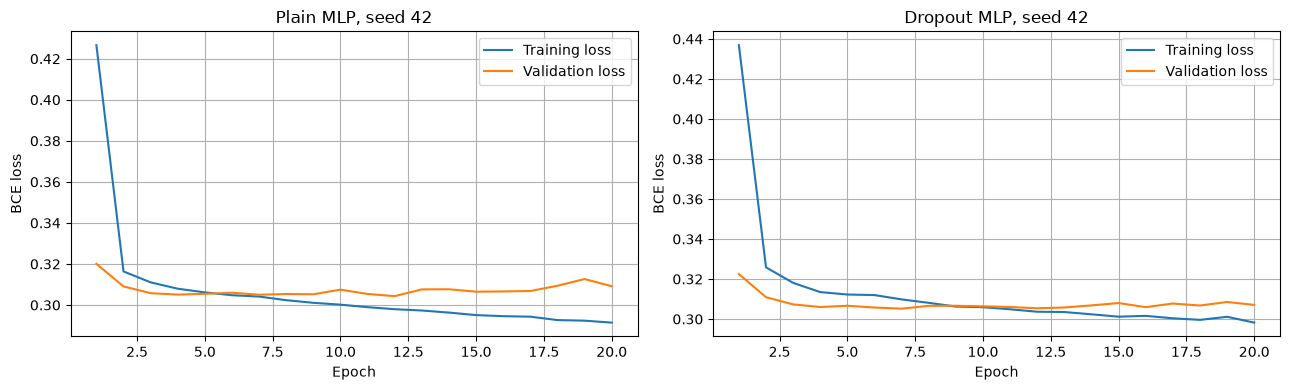

Plain MLP best validation epoch: 12
Start validation loss: 0.3201
Minimum validation loss: 0.3043
Last validation loss: 0.3092
Dropout MLP best validation epoch: 7
Start validation loss: 0.3225
Minimum validation loss: 0.3052
Last validation loss: 0.3071


In [14]:
Figure, Axes = plt.subplots(1, 2, figsize=(13, 4))

for Index, Name in enumerate(["Plain MLP", "Dropout MLP"]):
    TrainLoss, ValLoss = NetworkCurves[Name]
    EpochNumbers = list(range(1, len(TrainLoss) + 1))
    Axes[Index].plot(EpochNumbers, TrainLoss, label="Training loss")
    Axes[Index].plot(EpochNumbers, ValLoss, label="Validation loss")
    Axes[Index].set_title(Name + ", seed 42")
    Axes[Index].set_xlabel("Epoch")
    Axes[Index].set_ylabel("BCE loss")
    Axes[Index].legend()
    Axes[Index].grid(True)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

for Name in ["Plain MLP", "Dropout MLP"]:
    Losses = NetworkCurves[Name][1]
    BestEpoch = Losses.index(min(Losses)) + 1
    print(Name, "best validation epoch:", BestEpoch)
    print("Start validation loss:", round(Losses[0], 4))
    print("Minimum validation loss:", round(min(Losses), 4))
    print("Last validation loss:", round(Losses[-1], 4))

If validation loss increases after its minimum while training loss keeps falling, that is evidence of overfitting. Whether dropout helped should be judged from the validation curves and the five-run metrics, not assumed in advance.

## Final comparison and reproducible results

In [15]:
FinalRows = []
for Row in TestRows:
    FinalRows.append(Row.copy())

for Name in ["Plain MLP", "Dropout MLP"]:
    Row = {"Model": Name}
    for Metric in NetworkMetrics:
        Row[Metric] = NetworkMean.loc[Name, Metric]
    FinalRows.append(Row)

FinalTable = pd.DataFrame(FinalRows)
display(FinalTable.round(4))

print("The MLP rows are means of 5 seeded runs; the three classical rows are single test evaluations.")

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.8524,0.7414,0.5885,0.6562,0.9042
1,Random Forest,0.8602,0.7430,0.6356,0.6851,0.9038
2,Tuned Hist Gradient Boosting,0.8768,0.7929,0.6565,0.7183,0.9290
3,Plain MLP,0.8574,0.7406,0.6252,0.6766,0.9114
4,Dropout MLP,0.8580,0.7482,0.6140,0.6740,0.9123


The MLP rows are means of 5 seeded runs; the three classical rows are single test evaluations.


### README export

After all experiments finish, the final cell creates a `README.md` with the exact measured tables and learning-curve image. It replaces the README in the working folder.

In [16]:
import sys


def TableToMarkdown(Data):
    Names = Data.columns.tolist()
    Lines = ["| " + " | ".join(Names) + " |"]
    Lines.append("| " + " | ".join(["---"] * len(Names)) + " |")

    for _, Row in Data.iterrows():
        Values = []
        for Name in Names:
            Value = Row[Name]
            if isinstance(Value, (float, np.floating)):
                Values.append(f"{Value:.4f}")
            else:
                Values.append(str(Value))
        Lines.append("| " + " | ".join(Values) + " |")

    return "\n".join(Lines)


TrainMeanLoss = NetworkTable.groupby("Model")["Best validation loss"].mean()
BestCvName = CvTable.sort_values("ROC AUC mean", ascending=False).iloc[0]["Model"]
TestAucGap = roc_auc_score(YTest, BestProbabilities) - Search.best_score_

ReadmeParts = []
ReadmeParts.append("# Adult Income ML\n")
ReadmeParts.append("## Project summary\nThis project predicts whether a person earns more than 50K per year using the Adult dataset from OpenML, version 2. It compares classification pipelines and a PyTorch neural network.\n")
ReadmeParts.append("## Project files\n- `01_eda.ipynb`: dataset exploration (Part 1).\n- `02_models.ipynb`: preprocessing, model comparison, error analysis and PyTorch (Parts 2 to 4).\n- `figures/learning_curve.png`: training and validation loss for both networks.\n- `requirements.txt`: Python packages.\n")
ReadmeParts.append("## How to run\nTested notebook environment must include Python, numpy, pandas, scikit-learn, matplotlib, torch and jupyter. The notebook was generated and run using Python " + sys.version.split()[0] + ".\n")
ReadmeParts.append("```powershell\npy -m venv .venv\n.\\.venv\\Scripts\\python.exe -m pip install -r requirements.txt\n.\\.venv\\Scripts\\python.exe -m notebook\n```\n")
ReadmeParts.append("Run `01_eda.ipynb`, then `02_models.ipynb` using Restart Kernel and Run All Cells. The random seed for the train/test split is 42; the PyTorch experiments use seeds 42 to 46. OpenML downloads the dataset automatically.\n")
ReadmeParts.append("## Preprocessing and leakage prevention\nData is split 80/20 using stratification before fitting transformations. The preprocessing object imputes numeric missing values with the median, scales numeric columns, imputes categorical missing values using the most frequent category and one-hot encodes categories. The preprocessor is fitted only on training folds or the PyTorch training subset. The test set is never used to choose the model parameters.\n")
ReadmeParts.append("## Baselines: 5-fold CV\n" + TableToMarkdown(BaselineTable.round(4)) + "\n")
ReadmeParts.append("## Classical models: 5-fold CV\n" + TableToMarkdown(CvTable.round(4)) + "\n")
ReadmeParts.append("## Boosting parameter search\nTried values: " + str(ParameterGrid) + ".\n\nBest values: " + str(Search.best_params_) + ". Best CV ROC AUC: " + f"{Search.best_score_:.4f}" + ".\n")
ReadmeParts.append("## Final test-set comparison\n" + TableToMarkdown(FinalTable.round(4)) + "\n\nThe two MLP rows are means of five test-set evaluations with different training seeds. Each classical model has one final fitted-model evaluation. MLP results should not be treated as directly controlled comparisons because training uses an internal validation split.\n")
ReadmeParts.append("The highest baseline cross-validation ROC AUC among the three classical model families is achieved by **" + BestCvName + "**. The boosting model was tuned on training folds. No parameters were chosen using test-set scores. Boosting CV-to-test ROC AUC difference: " + f"{TestAucGap:+.4f}" + ". A small gap does not prove that leakage is absent.\n")
ReadmeParts.append("## Neural network training curves\n![Plain and dropout MLP learning curves](figures/learning_curve.png)\n\nBoth models use 64 and 32 hidden units, ReLU, BCEWithLogitsLoss, Adam (learning rate 0.001), batch size 256 and 20 epochs. Dropout is 0.2 in the regularised model. These are simple starting choices, not results of neural-network hyperparameter tuning.\n")
ReadmeParts.append("Neural network five-seed standard deviations:\n" + TableToMarkdown(NetworkStd.reset_index().round(4)) + "\n")
ReadmeParts.append("Mean minimum validation loss for Plain MLP: " + f"{TrainMeanLoss['Plain MLP']:.4f}" + "; for Dropout MLP: " + f"{TrainMeanLoss['Dropout MLP']:.4f}" + ". Compare those results and the plotted loss curves before claiming that dropout helped.\n")
ReadmeParts.append("## Error analysis\nThe notebook compares false negatives, true positives and true negatives by occupation, education number, working hours, capital gain and sex. Five errors are selected by distinct conditions, not just by row order. It also reports group-level precision and recall by sex and race.\n")
for Observation in ErrorObservations:
    ReadmeParts.append("- " + Observation + "\n")
ReadmeParts.append("\nGroup-level metrics:\n" + TableToMarkdown(GroupMetrics.round(4)) + "\n")
ReadmeParts.append("## Key findings\n- The majority-class dummy baseline shows why accuracy by itself is insufficient.\n- Stratified cross-validation reports variation across training folds.\n- Correlated features can share permutation importance.\n- The PyTorch networks use fewer weight-update rows because part of the training data is held out for validation.\n")
ReadmeParts.append("## Limitations and ethics\nThis is a demonstration experiment, not a model for employment, lending or individual decisions. The Adult census-style data is historical, may not represent current populations, and contains sensitive attributes such as sex and race. Proxy features can preserve group-related information even if sensitive attributes are removed. Before real use, check dataset representativeness, group-level errors, calibration, privacy and relevant regulations.\n")
ReadmeParts.append("## What was hard and what needs checking\nThe main challenges were making preprocessing reproducible, keeping CV separate from test evaluation, comparing MLP losses, and reporting numbers consistently. The complete notebook should be reviewed and rerun locally.\n")
ReadmeParts.append("## Target-label cleanup\nThe earlier code used `.rstrip('.')` on the target labels, but OpenML Adult version 2 does not add a trailing period to its labels. That operation was removed here. The provenance of that earlier line has not been established.")
ReadmeText = "\n".join(ReadmeParts)
ReadmeText = ReadmeText.replace("\\n", "\n")
Path("README.md").write_text(ReadmeText, encoding="utf-8")
print("Saved README.md and figures/learning_curve.png")

Saved README.md and figures/learning_curve.png
